## The Scientific Conclusion that is Correlation 

**Our Research Question:** Is the size of property `area_m2` a strong predictor of price rather than its location

<div class = "alert alert-block alert-success"><b>Correlation: Pearson Co-efficient (The Math)</b></div>

$$
r_{XY} = \frac{\sum_{i=1}^{n}(X_i-\bar{X})(Y_i-\bar{Y})}{\sqrt{\sum_{i=1}^{n}(X_i-\bar{X})^2}\sqrt{\sum_{i=1}^{n}(Y_i-\bar{Y})^2}}
$$

1) The Numerator ~ $Cov(X,Y) = \sum_{i=1}^{n}(X_i-\bar{X})(Y_i-\bar{Y})$:
   - For each observation `i` we calculate the the deviation of X and Y then take their product
   - summing accross al observations we get **a measure of the overall tendency to move together**

2)  The Denominator $\sqrt{\sum_{i=1}^{n}(X_i-\bar{X})^2}\sqrt{\sum_{i=1}^{n}(Y_i-\bar{Y})^2}$:
    - Is the product of the standard deviations without the $\frac{1}{n-1}$ factor (the sample) of X and Y. 

#### Interpretation bands
| Value | Interpretation |
|---|---|
| `r = 1.0` | Perfect positive linear relationship |
| `0.7 ≤ r < 1.0` | Strong positive relationship |
| `0.4 ≤ r < 0.7` | Moderate positive relationship |
| `0.1 ≤ r < 0.4` | Weak positive relationship |
| `-0.1 < r < 0.1` | No meaningful linear relationship |
| `-0.4 < r ≤ -0.1` | Weak negative relationship |
| `-0.7 < r ≤ -0.4` | Moderate negative relationship |
| `r = -1.0` | Perfect negative linear relationship |

<div class="alert alert-block alert-success"><b>Key Caveats</b></div>


   
1) **Pearson `r` (correl) only measures linear relationships** - A curved relationship (which is not linear) can result in a misrepresentation of there being no relationship
2) **Correlation does not imply causation** - Just because there is correlation it does not mean that X causes Y or that Y causes X 
3) **`r` is sensitive to outliers and sample size** - A big sample with massive extreme values makes it hard to estimate the r that best estimates the relationship between the data

  
we will compute correlation in pandas using:  
`series_a.corr(series_b)` -> Correlation between two specific collumns   
`df.corr` -> when we want a correlation matrix for the whole dataset/DataFrame 

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

data_path = "./data/mexico-real-estate-combined-clean.csv"

data = pd.read_csv(data_path)

print(f'Dimensions: {data.shape[0]} rows and {data.shape[1]} columns')
data.head()

Dimensions: 1736 rows and 6 columns


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


In [16]:
# Calculating the correlation between area_m2 and price_usd 

corr_price_area = (
    data["area_m2"]
    .corr(data["price_usd"])
)

print(f"The correlation (r) between Area m\u00b2 and Price is: {corr_price_area:.4f}")
print(f"The level of variability (r\u00b2) between Area m\u00b2 and Price is: {corr_price_area**2:.4f}")
print(f"It is not the variance which is \u03C3\u00b2")

The correlation (r) between Area m² and Price is: 0.5851
The level of variability (r²) between Area m² and Price is: 0.3424
It is not the variance which is σ²


**Statistical conclusion thus far** $\Rightarrow$ 34% of the variability in the property size (Area $m^{2}$) can be explained by the variability in the price of a property (price USD). The remaing 65% is explained by other factors such as location, property type, condition, amenities, and factors we have not measured. We are looking for variables to include into our regression model that have predictive power. However remember that there can be **indirect causality** (**another variable Z that causes Y** whom is strongly correlated to X) or multicollinearity.

<div class="alert alert-block alert-success"><b>Correlation Matrix and Heatmaps</b></div>

Correlation matrices are particularly useful at identifying quickly, amoung a set of numeric variable, which are worth investigating 

**However we cannot rely on the correlation matrix alone when**: 
1) When your relationships are non-linear (parabolas, hyperbolas, exponential functions, logarithmic functions, sine, cosine, arcsine...etc)
2) When you have categorical variables -  a variable that is non-numeric and puts data into qualitative groups
3) When your goal is a casual link and not a full mathematical and statistical realtionship 

We now compute the `correlation matrix`

In [4]:
#The Correlation Matrix and Heatmaps 
corr_matrix = (
    data
    .select_dtypes("number") # to select the numeric data only 
    .corr()                    # to calculate the pairwise correlations 
)
corr_matrix 

,lat,lon,area_m2,price_usd
lat,1.000000,-0.480231,0.082314,-0.083711
lon,-0.480231,1.000000,0.095522,0.031862
area_m2,0.082314,0.095522,1.000000,0.585134
price_usd,-0.083711,0.031862,0.585134,1.000000


`seaborn.heatmap()` parameters worth knowing:

| Parameter | What it does | Our choice |
|---|---|---|
| `annot=True` | Prints the numeric r value inside each cell | Keeps precision alongside the color |
| `cmap="coolwarm"` | Red = positive, Blue = negative, White = zero | Intuitive: hot = positive |
| `ax=ax` | Draws on our explicit Matplotlib Axes | Integrates with the explicit interface |
| `vmin=-1, vmax=1` | Pins the color scale to [-1, +1] | Optional but good practice |

Now we will visualise it with a heatmap using `seaborn`

<function matplotlib.pyplot.show(close=None, block=None)>

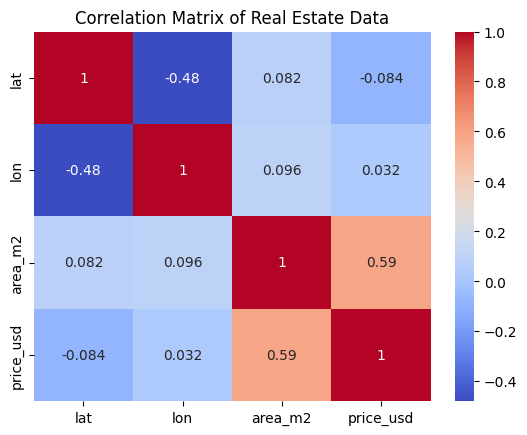

In [5]:
fig, ax = plt.subplots()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", ax=ax)

ax.set_title("Correlation Matrix of Real Estate Data")
plt.show 

**Note**: The correlation of lat and lon have nothing to do with real estate, they are just numeric variables that form part of the bgger picture of the data set 

This is a **geographical artifact**: Mexico is not a rectangular country. It narrows and tilts as you move north (toward higher latitude). The northernmost states (Baja California, Chihuahua) cluster at specific longitudes, while the southern states (Oaxaca, Chiapas) cluster at different longitudes. Moving north (increasing latitude) shifts which longitudes are represented — creating an apparent negative correlation. This tells us nothing about property prices. It is good practice to deduce the logic of unexpected correlations arising in the matrix. 

***Simpson's Paradox***: The global co-efficient can be partically misleading with relationships that exist as per the local instance of a state in mexico, meaning that this is a weighted average statistic showing a correlation that considers the whole sample (a set of sub-groups) rather than a individual cateory which may relay very different results. 


<div class="alert alert-block alert-success"><b>Segmented Correlations: Why Averages Lie</b></div>

`r` = 0.59 is now our national statistic or global coefficient that serves as the starting point to divulge. 

Logical proceeding hypothesis to test: 
1) is this relationship consistent across states?
2) If not what is the variability for a given state and state to state?

Why are these the logical points of inquery? because if the national number does not represent the state to state truth then it is an average of very different local markets. 

In [6]:
(
    data
    .head()
)

,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


<div class = "alert alert-block alert-success"><b>Correlation: State to State</b></div>

##### The following steps must be taken to comput the per state correlations:

1) **Split** the data by state
2) **Apply** .corr()
3) **Extract** the single numbers for `r` that wr care about
4) **Combine** the results into a ranked **Series**

This is the application of **Method Chaining** again. the recommended process that follows when chaining methods in a complex manner is to first conduct a slow and precise creation of the building blocks that will be required to build the end result. 

In [7]:
# Step 1) Split -  Isolate the relevant categories and attatch their nummerical sub-sets

(
    data
    .groupby("state")
    [["area_m2","price_usd"]]
)

In [8]:
# Step 2) Apply .corr() to each group 

(
    data
    .groupby("state")
    [["area_m2","price_usd"]]
    .corr()
    .head()
)

area_m2  price_usd
state                                             
Aguascalientes      area_m2    1.000000   0.897145
                    price_usd  0.897145   1.000000
Baja California     area_m2    1.000000   0.622471
                    price_usd  0.622471   1.000000
Baja California Sur area_m2    1.000000   0.810032

**Additional Step: 'Integer Location'** `.iloci[:, 1]` - select on the `price_usd` column:

In [9]:
(
    data
    .groupby("state")
    [["area_m2","price_usd"]]
    .corr()
    .iloc[:, 1]
    .head(10)
)

state                         
Aguascalientes       area_m2      0.897145
                     price_usd    1.000000
Baja California      area_m2      0.622471
                     price_usd    1.000000
Baja California Sur  area_m2      0.810032
                     price_usd    1.000000
Chiapas              area_m2      0.837629
                     price_usd    1.000000
Chihuahua            area_m2      0.926001
                     price_usd    1.000000
Name: price_usd, dtype: float64

`iloc` stands for **integer location** - selection by position number, not by label. What `.iloc[:,1]` means is that from all the rows `:`, give me only the values in the column at index position 1. Area ($m^{2}$) is at index positon 0 and price_usd is at index positon 1. in our `2 x 2 matrix` (price_usd x area, area x price_usd)

In [10]:
(
    data
    .groupby("state")
    [["area_m2","price_usd"]]
    .corr()
    .iloc[:, 1]
    .xs("area_m2", level=1)
    .head()
)

state
Aguascalientes         0.897145
Baja California        0.622471
Baja California Sur    0.810032
Chiapas                0.837629
Chihuahua              0.926001
Name: price_usd, dtype: float64

Now we compute the correlation by property type according to `price_usd` and `aream_m2`

In [11]:
# Calculate correlation by property_type
correlations_by_prop = (
    data
    .groupby("property_type")   # groupby `"property_type"`
    [["area_m2", "price_usd"]]    # we select by the `"area_m2"` and `"price_usd"` columns
    .corr()
    .iloc[:, 1]
    .xs("area_m2", level=1) # extracts the `"area_m2"` correlation value from the inner index level.
)

print(correlations_by_prop)

property_type
apartment    0.520902
house        0.718942
Name: price_usd, dtype: float64


Think about what drives the value of each property type:

| Apartment value drivers | House value drivers |
|---|---|
| Floor level (penthouse vs ground floor) | Size (larger = more rooms) |
| Building amenities (pool, gym, concierge) | Garden / outdoor space |
| Urban location (block, street, neighborhood) | Quiet neighborhood (subjective) |
| Natural light / orientation | Condition and finishes |
| Size — but competes with all of the above | Size — dominant factor |

Calculating `price_per_m2` using lambda and divdiding `price_usd` by `area_m2`

In [12]:
# Create new column
df = (
    data
    .assign(price_per_m2 = lambda x: x["price_usd"] / x["area_m2"])
)

df.head()

,property_type,state,lat,lon,area_m2,price_usd,price_per_m2
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56,453.103733
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78,339.912796
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37,1028.028902
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80,628.725333
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37,513.128634


That's the end of this part!